# Can a learned certificate generalize?
### An interactive experiment for Lemma 6 → Theorem 7

**Freeze the controller. Fit only the certificate. Compare sample loss with the exact population loss.**

This notebook accompanies [the problem formulation](../ese6180/Evaluation_Guided_Domain_Randomization/Report_Sections/02_problem_formulation.tex) and [the design notes](../ese6180/proposal/discussions/proposal-design-notes.md). It follows the phase-plane, seed-inspection, and sample-size-sweep ideas of the RL Atlas **Flows and certificates** lab, with the exact loss and bounded candidate class from this report.

**Start here:** Run All, then rotate the ellipse, inspect different dataset seeds, and run the unstable-plant sweep. Every section includes a saved static figure; live controls need an active Python kernel and widget support.

From the repository root, install the optional notebook dependencies:
```bash
uv sync --group notebooks
```
Open this notebook in VS Code/Jupyter and choose the repository's `.venv` Python kernel. For a standalone JupyterLab session:
```bash
uv run --group notebooks --with jupyterlab jupyter lab notebooks/certificate_generalization.ipynb
```

The numerical support module uses NumPy only. No policy training, GPU, or network access is needed during the experiment.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

# Work from either the repository root or notebooks/, including headless execution.
ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "src/active_eval_gym/certificates.py").is_file()
)
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks"))

In [2]:
import matplotlib.pyplot as plt
from certificate_widgets import (
    bound_controls,
    dataset_controls,
    geometry_controls,
    plot_bound,
    plot_certificate,
    plot_dataset,
    plot_sweep,
    prepare_lab,
    setup_card,
    sweep_controls,
    sweep_summary,
)
from IPython.display import display

from active_eval_gym.certificates import (
    KNOWN_CERTIFICATE,
    CertificateSpec,
    loss_table,
    run_sweep,
    verified_margins,
)

%matplotlib inline
SPEC = CertificateSpec()
LAB = prepare_lab(SPEC)
display(setup_card(LAB))

## 1. Declare the experiment before drawing data

The two closed-loop plants are
$$
G_1=\begin{pmatrix}0.8&0.5\\0&0.6\end{pmatrix},\qquad
G_2=\begin{pmatrix}0.7&0.6\\0&0.5\end{pmatrix}.
$$
They can be realized as $A(\theta)=G_\theta+I$, $B(\theta)=I$, with the same **frozen gain $K=I$**, so $u=-Kx$ and $A-BK=G_\theta$. Dynamics and observations are exact matrix operations; there is no saturation or early termination. Both plants are stable, although $G_1$ can stretch Euclidean distance in some directions for one step.

We fix $H=10$, $a=0.5$, $b=2$, $\eta=0.02$, $\gamma=0.1$. Each episode chooses a plant with probability $1/2$ and a reset uniformly from **64 equally spaced directions on the unit circle**; the plant stays fixed for all 10 transitions.

This is a deliberately finite sampling law supported inside the theorem's unit ball. It is **not** uniform over the ball. Its 128 trajectories let us compute true population averages by enumerating the whole law:
$$
L_K(P)=\sum_j w_j\ell_P(\tau_j),\qquad
e_{K,H}(P)=\sum_j w_j\mathbf1\{s_P(\tau_j)>0\}.
$$
Training datasets contain $N$ independent draws **with replacement** from this law. A trajectory is one sample, even though it contains 10 transitions. Population enumeration is used for diagnostics only; certificate fitting sees the sampled indices.

The deterministic candidate grid contains rotated matrices with eigenvalues in $[a,b]$, plus the known certificate $P_0=\operatorname{diag}(0.6,1.6)$. Raw states, loss computation, and fitting are separate functions in [certificates.py](../src/active_eval_gym/certificates.py).

All computations use float64 arithmetic. Population enumeration is exact for the declared finite law up to floating-point error. The displayed stable-plant eigenvalue check uses tolerance $10^{-10}$; trajectory violation uses the strict test $s_P>0$. Risk-bound exceedance counts allow $10^{-12}$ for roundoff. These settings are recorded on export.

In [3]:
print("Closed-loop matrices (gain K = I remains fixed):")
for i, g in enumerate(LAB.population.matrices, start=1):
    print(f"G{i} =\n{g}")
print(f"\nCandidate count: {len(LAB.grid.matrices):,}")
print(f"Conservative grid covering radius ρ: {LAB.grid.covering_radius:.4f}")
print(
    "P₀ all-state decrease margins:",
    verified_margins(LAB.population.matrices, KNOWN_CERTIFICATE),
)
known = loss_table(LAB.population, KNOWN_CERTIFICATE)
print(f"P₀ exact population loss: {known.population_loss[0]:.6f}")
print(f"P₀ exact violation probability: {known.population_risk[0]:.6f}")

Closed-loop matrices (gain K = I remains fixed):
G1 =
[[0.8 0.5]
 [0.  0.6]]
G2 =
[[0.7 0.6]
 [0.  0.5]]

Candidate count: 874
Conservative grid covering radius ρ: 0.2713
P₀ all-state decrease margins: [0.1377642  0.22259616]
P₀ exact population loss: 0.000000
P₀ exact violation probability: 0.000000


## 2. Shape the certificate and watch the trajectories

A certificate $V_P(x)=x^\top Px$ assigns an energy to every state. The level set $V_P=1$ is an ellipse. The spectral bounds keep it between circles of radii $1/\sqrt b$ and $1/\sqrt a$.

For each nonzero transition, the normalized residual is
$$
r_P(x,x^+)=\frac{V_P(x^+)-V_P(x)}{\|x\|^2}+\eta.
$$
The worst residual $s_P$ along a trajectory determines its loss:
$$
\ell_P=\operatorname{clip}(1+s_P/\gamma,0,1).
$$
**Read the four panels:** geometry; worst residual versus reset direction; energy versus Euclidean distance; and the ramp that converts residual to loss. A residual between $-\gamma$ and zero satisfies the desired condition but still pays a positive loss.

**Try:** rotate the known ellipse by 90°. Use Play or scrub transition $t$ to follow the trajectory. Then preview the unstable plant $G_3=1.02I$. Changing $P$ changes our assessment of the same trajectories; it does not change the dynamics. The unstable preview explicitly uses the 10% stress distribution.

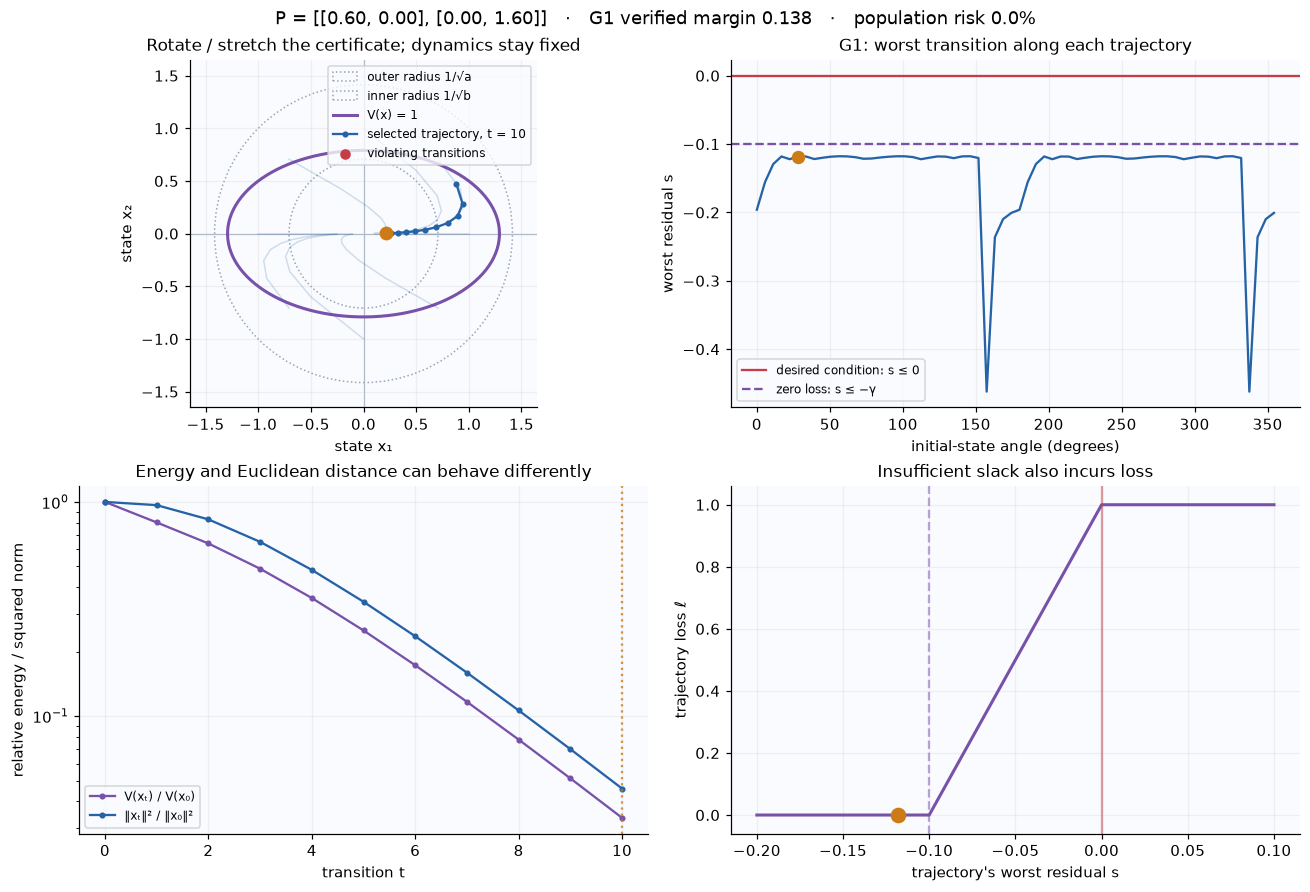

In [4]:
fig = plot_certificate(LAB)
plt.show()
plt.close(fig)

In [5]:
display(geometry_controls(SPEC))

## 3. Fit on one dataset, inspect the entire population

For each dataset, we minimize empirical loss over the **fixed candidate grid**. Ties go to the first grid index, independent of population performance. The orange star is the fitted matrix; the red diamond has the largest absolute generalization gap among grid candidates. Switching to that diamond illustrates why the theorem needs a guarantee for every candidate simultaneously.

In the middle panel, the diagonal means perfect agreement between empirical and population loss. The shaded band is the theorem's allowance $\pm\Delta_N$. In the right panel, dots mark sampled resets while curves show the full population. The reset distribution is discrete; connecting lines are visual guides between its support points.

**Try:** use $N=4$ and vary the dataset seed. Increase $N$ while keeping the seed fixed. The datasets use nested prefixes, so more trajectories are added without replacing the original ones. Then switch to the 10% unstable case.

The selector is for inspection only. The repeated experiment below uses every predeclared seed, with no performance-based omission.

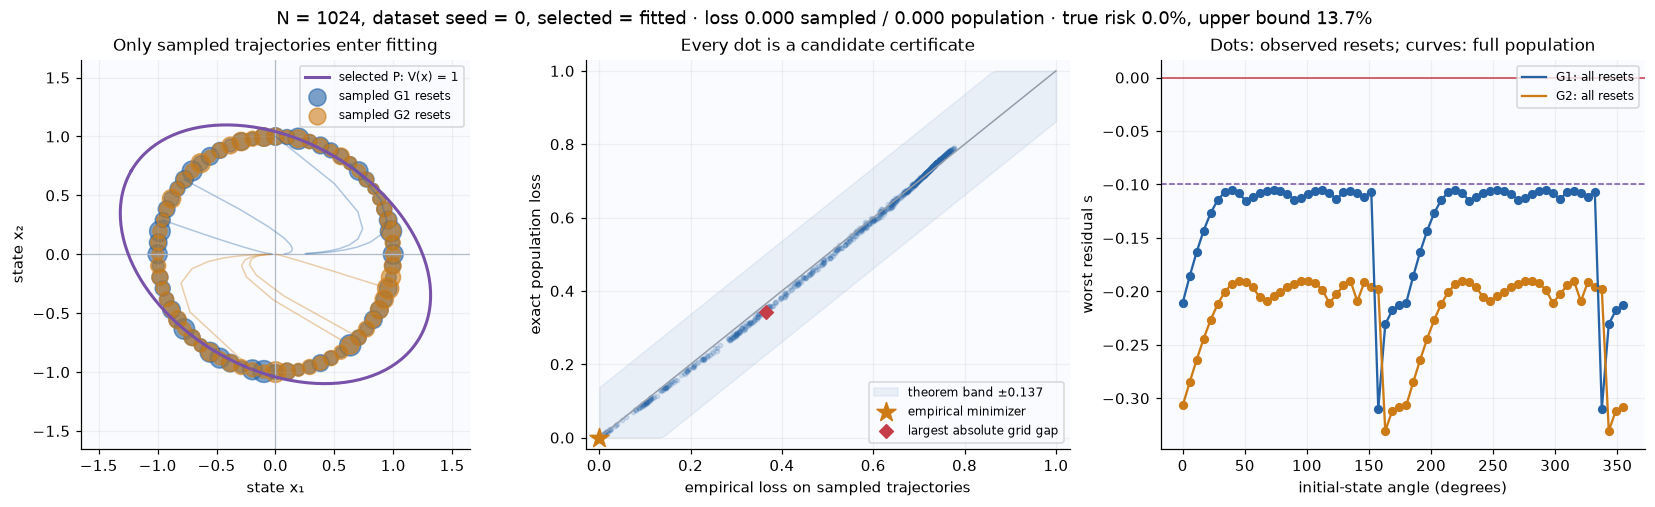

In [14]:
fig = plot_dataset(LAB, n=1024, seed=0)
plt.show()
plt.close(fig)

In [7]:
display(dataset_controls(SPEC))

## 4. Repeat the experiment across datasets

For each $N\in\{32,128,512,2048,8192\}$, we draw 100 datasets using replicate IDs 0–99 and master seed 6180. Replicates have separate random streams; sample sizes share prefixes within a replicate. The selected resolution $\varepsilon$ depends only on the declared constants and $N$, never on sampled performance.

Each dataset produces:

- the fitted certificate's absolute gap $|L_K(\widehat P)-\widehat L_{N,K}(\widehat P)|$;
- the largest absolute gap over the candidate grid;
- exact violation probability $e_{K,H}(\widehat P)$ and its training-based upper bound $\min\{1,\widehat L_{N,K}(\widehat P)+\Delta_N\}$.

Shaded bands show the 10th–90th percentiles across datasets, **not confidence intervals for population risk**. The final panel counts bound exceedances and gives pointwise 95% Wilson intervals for their frequency across independent datasets. The theorem permits an exceedance probability of at most $\delta=0.05$ for each fixed $N$; it does not predict that 5% of runs must fail.

The default stable case is intentionally easy: fitted risk and fitted gap can be identically zero. The largest-grid-gap curve still probes how the same dataset assesses other matrices. The stress case in the next section creates a nonzero loss floor and more visible fitted-loss fluctuations.

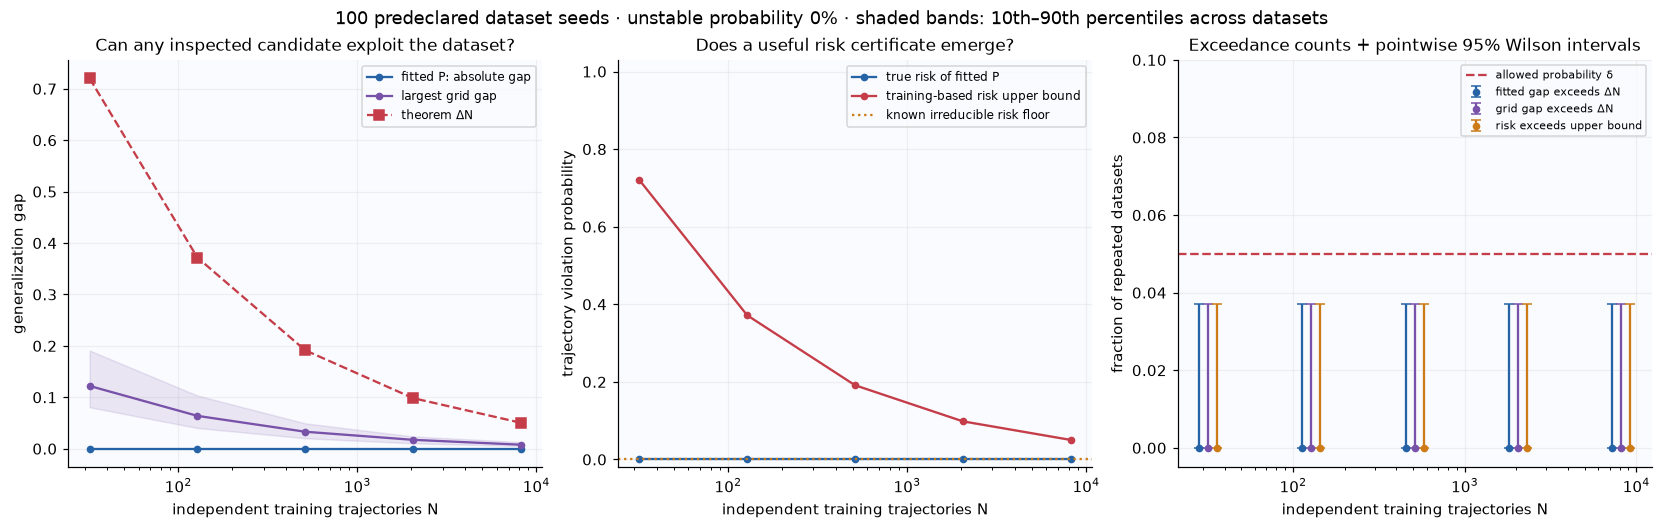

N,theoretical ε,ΔN,median fitted gap,largest observed grid gap,grid exceedances
32,0.00084,0.720,0.0000,0.2355,0/100
128,0.00041,0.372,0.0000,0.1840,0/100
512,0.0002,0.191,0.0000,0.0661,0/100
"2,048",9.6e-05,0.098,0.0000,0.0392,0/100
"8,192",4.6e-05,0.051,0.0000,0.0187,0/100


In [8]:
DEFAULT_SWEEP = run_sweep(LAB.population, LAB.grid, LAB.table, replicates=100)
fig = plot_sweep(LAB, DEFAULT_SWEEP)
plt.show()
plt.close(fig)
display(sweep_summary(DEFAULT_SWEEP))

## 5. An unstable plant that no certificate can hide

Now choose the original plants with probability 0.45 each and $G_3=1.02I$ with probability 0.10. Every nonzero state expands under $G_3$. Therefore every positive-definite candidate violates there and incurs loss one.

The known $P_0$ still gives loss zero on both stable plants. Consequently the **best possible population loss and violation risk are both exactly 0.10**. Empirically, $P_0$ attains the fraction of unstable episodes in the dataset, a lower bound that no candidate can beat. Since the grid includes $P_0$, its empirical minimum is also a minimum over the full bounded class for these declared settings, up to numerical precision.

This makes a useful diagnostic: a dataset that happens to contain few unstable episodes understates the population loss. The theorem's allowance must cover that sampling fluctuation. Changing $P$ cannot remove the true 10% floor.

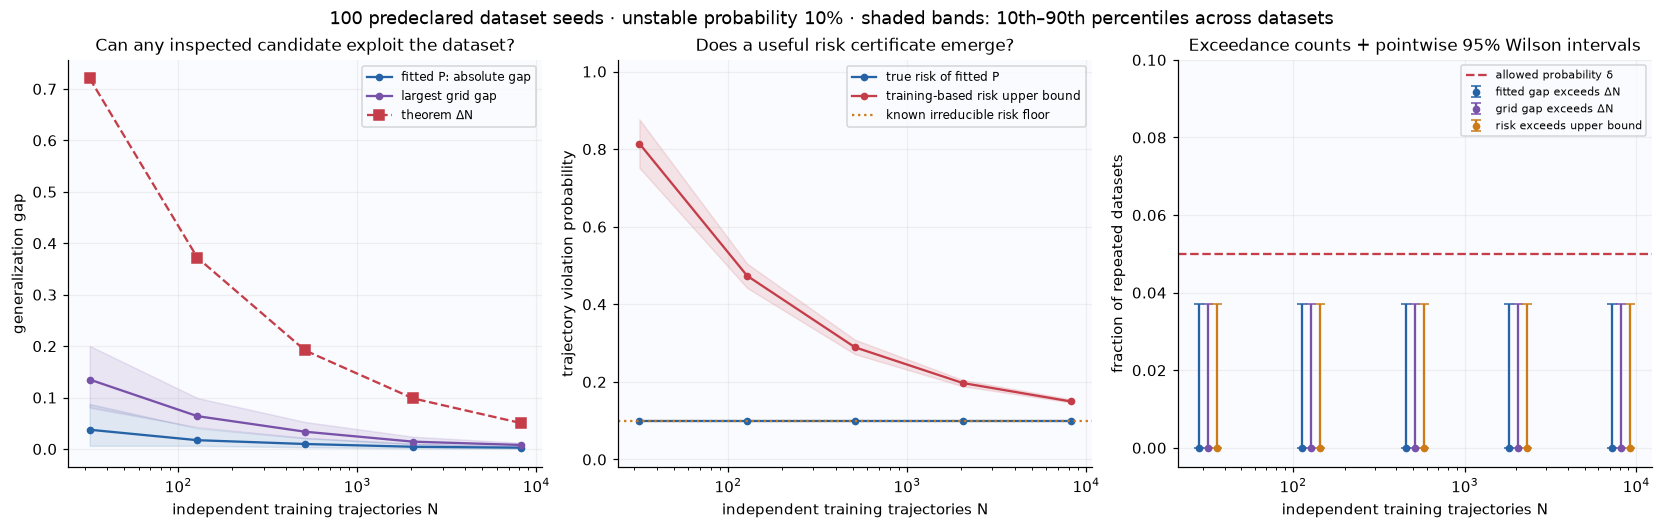

N,theoretical ε,ΔN,median fitted gap,largest observed grid gap,grid exceedances
32,0.00084,0.720,0.0375,0.2813,0/100
128,0.0004,0.372,0.0172,0.1299,0/100
512,0.0002,0.192,0.0098,0.0729,0/100
"2,048",9.5e-05,0.098,0.0044,0.0380,0/100
"8,192",4.6e-05,0.051,0.0026,0.0158,0/100


In [9]:
STRESS_LAB = prepare_lab(replace(SPEC, unsafe_probability=0.1))
STRESS_SWEEP = run_sweep(
    STRESS_LAB.population,
    STRESS_LAB.grid,
    STRESS_LAB.table,
    replicates=100,
)
fig = plot_sweep(STRESS_LAB, STRESS_SWEEP)
plt.show()
plt.close(fig)
display(sweep_summary(STRESS_SWEEP))

### Run your own sweep and export it

The controls below run 50, 100, or 500 predeclared datasets per sample size. Changing a control takes effect only when **Run sweep** is pressed. The initial export target is the default stable sweep above; after a run, export saves that last completed run.

By default, $\delta=0.05$ applies separately to each fixed $N$. Check **joint guarantee** to allocate $0.05/5$ to each of the five sample sizes, obtaining a union-bound guarantee across those sizes for a replicate. This concerns sample sizes, not simultaneous coverage over all future notebook settings.

**Export current run** creates a new timestamped directory under `artifacts/certificate_generalization/`. It retains the full raw population trajectories and actual training-draw indices separately from versioned derived metrics, together with policy/plant specifications, seeds, package versions, and source hashes. Nothing is exported automatically during Run All.

In [10]:
display(sweep_controls(SPEC, ROOT, DEFAULT_SWEEP))

## 6. Open the bound and inspect its moving parts

Lemma 6 supplies a bound on the size of a theoretical $\varepsilon$-net. Hoeffding and a union bound control every representative. Lipschitz continuity then introduces **two approximation errors**, one for the population average and one for the empirical average:
$$
\Delta_N(\varepsilon,\delta)
=\underbrace{2L_{\rm par}\varepsilon}_{\text{two approximation errors}}
+\underbrace{\sqrt{\frac{3\log(1+2b\sqrt2/\varepsilon)+\log(2/\delta)}{2N}}}
_{\text{concentration over the finite net}},\qquad
L_{\rm par}=\frac{M_K^2+1}{\gamma}.
$$

Smaller $\varepsilon$ improves approximation but requires more representatives. The star marks the best resolution on a fixed search grid chosen using constants alone. Moving the slider evaluates another predeclared resolution; it does not select one by observed generalization performance.

**Two distinct grids:** the candidate grid used for numerical fitting has covering radius $\rho$ shown above. The theoretical net at resolution $\varepsilon$ is a proof device and is never enumerated. The bound remains valid for every candidate in the numerical grid because those candidates lie in the full class. We do not substitute the small computational grid's size into the full-class theorem.

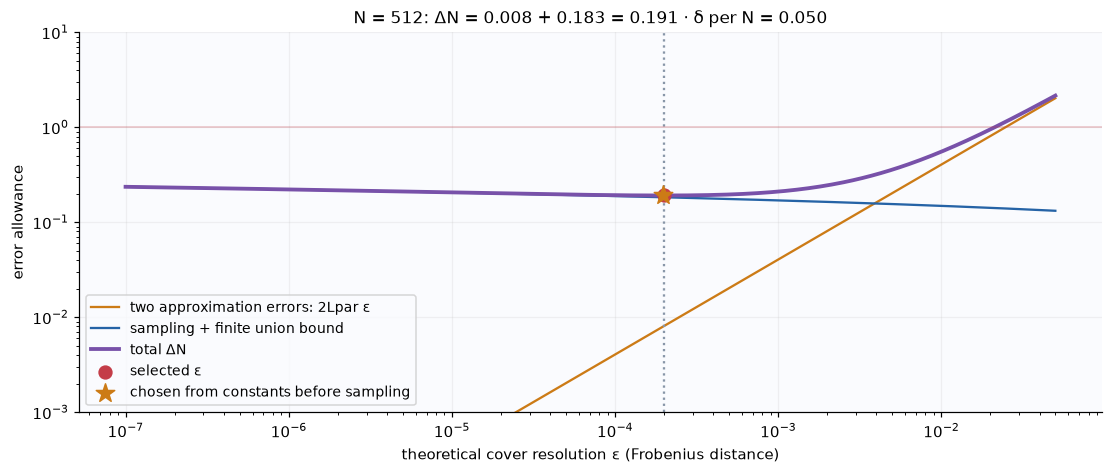

In [11]:
fig = plot_bound(LAB)
plt.show()
plt.close(fig)

In [12]:
display(bound_controls(LAB))

## 7. What the experiment establishes

**A useful numerical check:** compare true and empirical losses, look for bound exceedances across independent datasets, inspect how loose the bound is, and confirm that it approaches the known risk floor as $N$ grows. No exceedances is consistent with a conservative guarantee; it does not prove the theorem.

**A finite grid is not the whole class.** Its largest observed gap is a lower bound on the supremum over all $P$. The grid has an explicit conservative covering-radius bound $\rho$. Lipschitz continuity also gives a full-class upper bound $g_{\rm full}\le g_{\rm grid}+2L_{\rm par}\rho$, but for this coarse interactive grid that allowance is usually too large to help. Neither a grid inspection nor finite Monte Carlo establishes uniformity over the continuous class.

**Generalization and stability remain separate.** The risk guarantee concerns the specified reset/plant law over 10 transitions. The independent eigenvalue test $\lambda_{\min}(P-G_\theta^\top P G_\theta)$ is the all-state verification step. The setup card verifies the known $P_0$; inspecting one learned matrix's trajectories is not an all-state certificate.

**Optimization is explicit.** Fitting is exact over the finite grid. For the fixed settings used here, the known matrix attains the empirical lower bound from unstable draws, so the grid minimum is also a full-class empirical minimum. If you edit the margins or class, this property must be rechecked. In general a grid fit only guarantees optimization tolerance at most $L_{\rm par}\rho$ relative to the full class; the clipped loss is not a convex objective. The deviation and risk bounds do not require globally optimal fitting.

**Reproducibility:** configuration is declared before sampling; weights and gain remain frozen; every replicate is retained; raw states are independent of metric computation; exports are versioned. Dataset selection controls are for exploration and never filter the sweep.

Suggested discussion questions:

1. Why does the largest grid gap stay nonzero when the fitted certificate's gap is zero?
2. Why does adding the unstable plant create an irreducible floor rather than invalidate the generalization theorem?
3. Why does the bound shrink with $N$ even when true risk stops improving?
4. Why would replacing $N$ by $NH$ count the same trajectory evidence more than once?
5. Which parts would need a different argument before applying this to the quantized CartPole policy?